# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Вариант CV.** Детектор YOLO26n, [BCCD](https://github.com/Shenggan/BCCD_Dataset) (MIT). Обязательные разделы 1–5, без бонусов. Источники кода и методики — шаблон ДЗ-2 и [документация Ultralytics](https://docs.ultralytics.com/modes/train/). Устройство — Apple M4 (MPS).

In [1]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
from importlib.metadata import version
if importlib.util.find_spec('ultralytics') is None or version('ultralytics') != '8.4.40':
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.40'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.40, torch 2.15.0, device: mps


In [2]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = set()     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2') / ('fast' if FAST_MODE else 'full')
IMGSZ = 320 if FAST_MODE else 384
EPOCHS = 2 if FAST_MODE else 12
BATCH = 8 if FAST_MODE else 8
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if sys.platform in ('win32', 'darwin') else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
WEIGHTS = 'yolo26n.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
digest = hashlib.sha256(weights_path.read_bytes()).hexdigest()
assert digest == '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef'
MODEL_INFO = dict(weights=WEIGHTS, sha256=digest, ultralytics=ultralytics.__version__,
                  size_mb=weights_path.stat().st_size / 1e6, n_classes_coco=len(model_coco.names),
                  params=sum(p.numel() for p in model_coco.model.parameters()))
sample = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)
def sync():
    if DEVICE == 'mps':
        torch.mps.synchronize()
    elif torch.cuda.is_available():
        torch.cuda.synchronize()
for _ in range(3):
    model_coco.predict(sample, imgsz=IMGSZ, verbose=False, device=DEVICE)
sync()
start = time.perf_counter()
for _ in range(15):
    model_coco.predict(sample, imgsz=IMGSZ, verbose=False, device=DEVICE)
sync()
MODEL_INFO['latency_ms'] = (time.perf_counter() - start) * 1000 / 15

In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'ultralytics': '8.4.40',
 'size_mb': 5.544453,
 'n_classes_coco': 80,
 'params': 2572280,
 'latency_ms': 6.08996666657428}

Для BCCD выбрана YOLO26n: на 205 обучающих снимках можно быстро сравнить обычное обучение и заморозку backbone. При входе 640 для n/s опубликованы соответственно 2,4/9,5 млн параметров после слияния слоёв, 40,1/47,8% end-to-end mAP50–95 на COCO и 1,7/2,5 мс на T4 TensorRT. На M4 полный вызов predict для одного кадра 384 × 384 занял в среднем 6,1 мс по 15 запускам после прогрева. Код и веса доступны по AGPL-3.0: при распространении производной работы сохраняют лицензию и предоставляют соответствующий исходный код; при сетевом использовании изменённой программы пользователям также предоставляют доступ к её исходникам. [Таблица моделей](https://docs.ultralytics.com/models/yolo26/) · [Лицензия](https://www.ultralytics.com/license)

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [6]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect
    groups = dict(backbone=layers[:n_backbone], neck=layers[n_backbone:-1], head=layers[-1])
    return {name: sum(p.numel() for p in block.parameters()) for name, block in groups.items()}


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    features = []
    def capture(module, args):
        features.extend(tuple(x.shape) for x in args[0])
    hook = det_model.model[-1].register_forward_pre_hook(capture)
    training = det_model.training
    try:
        det_model.eval()
        with torch.no_grad():
            ref = next(det_model.parameters())
            output = det_model(ref.new_zeros(1, 3, imgsz, imgsz))
    finally:
        hook.remove()
        det_model.train(training)
    return features, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [7]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [8]:
print(shapes(out))

[(1, 300, 6), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


Backbone извлекает признаки с шагами 8, 16 и 32 пикселя. Neck объединяет детальные и семантические карты через увеличение разрешения, конкатенации и обратный проход вниз. Для входа 640 получается 80² + 40² + 20² = 8400 позиций. Для каждой позиции голова предсказывает оценки классов и четыре расстояния до сторон рамки. Такая схема называется anchor-free: размеры и пропорции рамок не задаются заранее. При обучении one2many назначает объект нескольким позициям, one2one учится выдавать одну детекцию на объект. При выводе через one2one достаточно выбрать лучшие предсказания без NMS. Из 2 572 280 параметров на backbone приходится 53%, на neck — 35%, на Detect — 12%.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [9]:
from urllib.request import urlretrieve
from zipfile import ZipFile

revision = 'd272fb14cdff6e473fafeeeba32aba5f560e9e43'
root = DATA_ROOT / f'BCCD_Dataset-{revision}' / 'BCCD'
if not (root / 'ImageSets/Main/test.txt').exists():
    DATA_ROOT.mkdir(exist_ok=True)
    archive, _ = urlretrieve(f'https://codeload.github.com/Shenggan/BCCD_Dataset/zip/{revision}')
    with ZipFile(archive) as z:
        z.extractall(DATA_ROOT)
CLASSES = ['RBC', 'WBC', 'Platelets']
DATASET_NAME = f'BCCD, https://github.com/Shenggan/BCCD_Dataset/tree/{revision}, MIT'
repairs = Counter()
records = {}
for split in ('train', 'val', 'test'):
    records[split] = []
    for stem in (root / f'ImageSets/Main/{split}.txt').read_text().split():
        xml = ET.parse(root / f'Annotations/{stem}.xml')
        image = root / f'JPEGImages/{stem}.jpg'
        with Image.open(image) as im:
            w, h = im.size
        assert (w, h) == tuple(int(xml.findtext('size/' + k)) for k in ('width', 'height'))
        boxes, labels = [], []
        for obj in xml.findall('object'):
            raw = np.array([float(obj.findtext('bndbox/' + k)) for k in ('xmin', 'ymin', 'xmax', 'ymax')])
            raw[:2] -= 1  # VOC: первый пиксель имеет индекс 1; xyxy хранит правую границу исключительной
            box = np.clip(raw, 0, [w, h, w, h])
            repairs['clipped'] += int(np.any(raw != box))
            if np.any(box[2:] <= box[:2]):
                repairs['dropped'] += 1
                continue
            boxes.append(box)
            labels.append(CLASSES.index(obj.findtext('name').strip()))
        records[split].append(dict(image=image, width=w, height=h, boxes=np.asarray(boxes, np.float32).reshape(-1, 4),
                                   labels=np.asarray(labels, np.int64)))
images = [r['image'] for group in records.values() for r in group]
assert len(images) == len(set(images))
print('Исправлено границ:', repairs['clipped'], 'удалено боксов:', repairs['dropped'])

Исправлено границ: 0 удалено боксов: 0


In [10]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 205, 'val': 87, 'test': 72}

train {'RBC': 2382, 'WBC': 214, 'Platelets': 209} объектов/кадр (среднее, максимум): 13.68 28
val {'RBC': 968, 'WBC': 87, 'Platelets': 83} объектов/кадр (среднее, максимум): 13.08 30
test {'RBC': 805, 'WBC': 71, 'Platelets': 69} объектов/кадр (среднее, максимум): 13.12 24
RBC медианная доля площади кадра: 0.0345
WBC медианная доля площади кадра: 0.117
Platelets медианная доля площади кадра: 0.0051


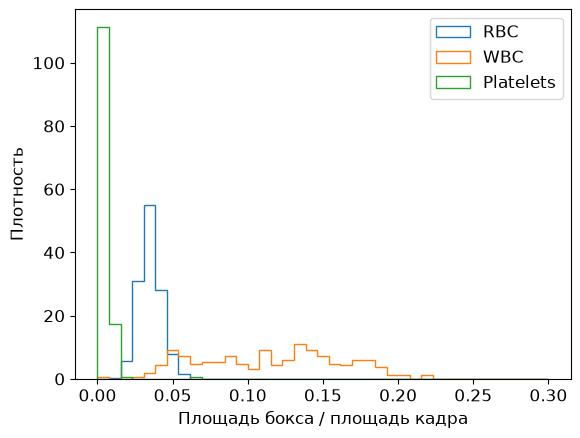

In [11]:
for split, recs in records.items():
    counts = np.bincount(np.concatenate([r['labels'] for r in recs]), minlength=len(CLASSES))
    density = [len(r['boxes']) for r in recs]
    print(split, dict(zip(CLASSES, counts.tolist())), 'объектов/кадр (среднее, максимум):', np.mean(density).round(2), max(density))
for k, name in enumerate(CLASSES):
    areas = []
    for r in records['train']:
        boxes = r['boxes'][r['labels'] == k]
        areas.extend(np.prod(boxes[:, 2:] - boxes[:, :2], axis=1) / (r['width'] * r['height']))
    plt.hist(areas, bins=np.linspace(0, .3, 40), histtype='step', density=True, label=name)
    print(name, 'медианная доля площади кадра:', round(float(np.median(areas)), 4))
plt.xlabel('Площадь бокса / площадь кадра'); plt.ylabel('Плотность'); plt.legend(); plt.show()

Использованы исходные списки train, val и test репозитория BCCD. На одном снимке мазка встречается много эритроцитов (RBC), заметно меньше лейкоцитов (WBC) и тромбоцитов (Platelets). У тромбоцитов самые маленькие боксы, поэтому изменение границы на несколько пикселей сильнее влияет на их IoU. В train, val и test соответственно 205, 87 и 72 снимка. В train на 2382 RBC приходится 214 WBC и 209 тромбоцитов. Медианная площадь рамки тромбоцита — 0,51% кадра, лейкоцита — 11,7%. При чтении XML не встретилось вырожденных боксов или координат за границами изображения.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [12]:
def to_yolo(boxes, labels, width, height):
    lines = []
    for (x1, y1, x2, y2), label in zip(boxes, labels):
        coords = ((x1+x2)/(2*width), (y1+y2)/(2*height), (x2-x1)/width, (y2-y1)/height)
        lines.append(str(int(label)) + ' ' + ' '.join(f'{x:.6f}' for x in coords))
    return '\n'.join(lines)


def from_yolo(text, width, height):
    boxes, labels = [], []
    for line in text.strip().splitlines():
        label, cx, cy, w, h = line.split()
        cx, cy, w, h = map(float, (cx, cy, w, h))
        boxes.append([(cx-w/2)*width, (cy-h/2)*height, (cx+w/2)*width, (cy+h/2)*height])
        labels.append(int(label))
    return np.asarray(boxes, np.float32).reshape(-1, 4), np.asarray(labels, np.int64)

In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    images = YOLO_ROOT / 'images' / split
    labels = YOLO_ROOT / 'labels' / split
    images.mkdir(parents=True, exist_ok=True)
    labels.mkdir(parents=True, exist_ok=True)
    for r in recs:
        image = Path(r['image'])
        shutil.copyfile(image, images / image.name)
        (labels / (image.stem + '.txt')).write_text(to_yolo(r['boxes'], r['labels'], r['width'], r['height']))


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: /Users/kolya/Documents/university/глубокое обучение/hw2_students/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: RBC
  1: WBC
  2: Platelets



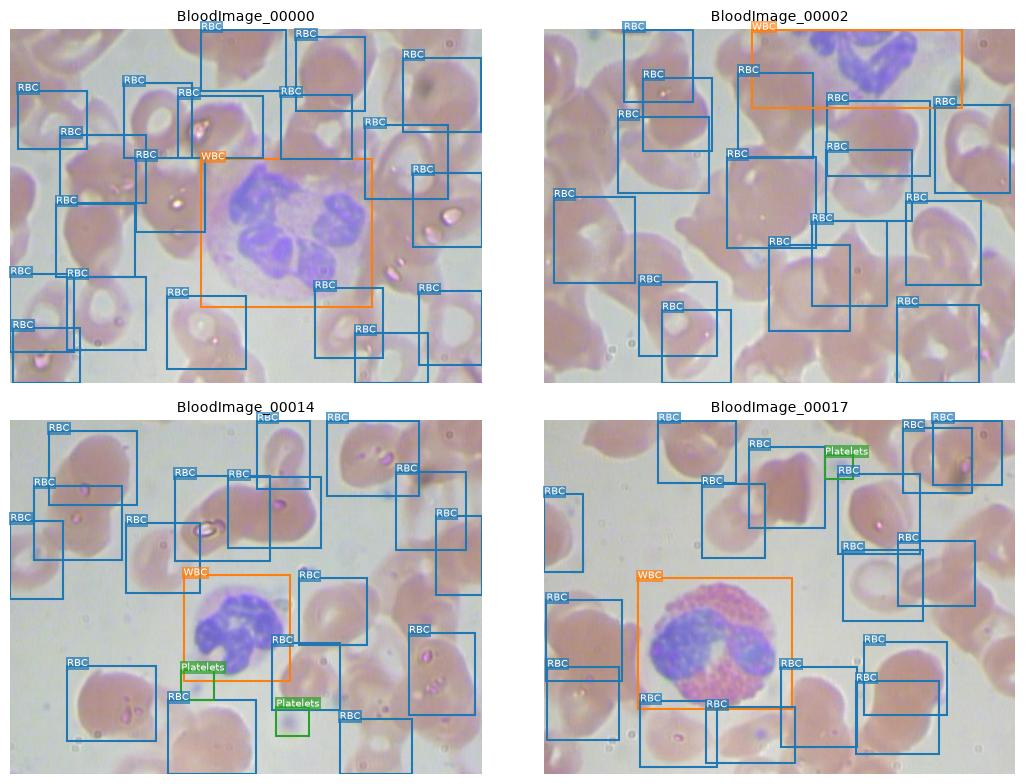

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for i, r in enumerate(splits['val']):
    label_file = YOLO_ROOT / 'labels/val' / (r['image'].stem + '.txt')
    boxes, labels = from_yolo(label_file.read_text(), r['width'], r['height'])
    assert np.allclose(boxes, r['boxes'], atol=.002) and np.array_equal(labels, r['labels'])
    if i < 4:
        draw_boxes(axes.flat[i], Image.open(r['image']), boxes, labels, CLASSES, title=r['image'].stem)
plt.tight_layout(); plt.show()

Обратное чтение проверяет сохранность порядка, классов и координат с точностью округления. Эталонная строка тестирует соглашение о центре и нормировке. Если обе функции одинаково перепутают ширину и высоту, исходные координаты могут восстановиться даже при неправильной записи в файл. На изображении такую ошибку видно по смещению или растяжению рамок.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

In [16]:
coco_preds = predict_records(model_coco, records[FINAL_SPLIT])
top_labels = Counter(model_coco.names[int(k)] for pred in coco_preds for k in pred['labels'][pred['scores'] >= .05])
print('Частые COCO-классы при conf ≥ .05:', top_labels.most_common(8))
assert set(CLASSES).isdisjoint(model_coco.names.values())
empty = dict(boxes=np.empty((0, 4)), labels=np.empty(0, int), scores=np.empty(0))
coco_map50, _ = evaluate_map50([empty] * len(coco_preds), records[FINAL_SPLIT], len(CLASSES))

Частые COCO-классы при conf ≥ .05: [('donut', 66), ('cake', 50), ('bed', 34), ('dining table', 25), ('orange', 8), ('teddy bear', 5), ('keyboard', 4), ('person', 3)]


In [17]:
def heuristic_detect(image_path):
    rgb = np.asarray(Image.open(image_path).convert('RGB'), dtype=float) / 255
    # Фиолетовые ядра и тромбоциты: синий и красный каналы сильнее зелёного.
    purple = (rgb[:, :, 2] - rgb[:, :, 1] > .16) & (rgb[:, :, 0] - rgb[:, :, 1] > .08)
    mask = ndimage.binary_closing(purple, iterations=2)
    components, _ = ndimage.label(mask)
    boxes, scores, labels = [], [], []
    for idx, sl in enumerate(ndimage.find_objects(components), 1):
        y, x = sl
        area = np.count_nonzero(components[sl] == idx)
        if area < 20:
            continue
        cls = 1 if area > 500 else 2
        w, h = typical_wh[cls]
        cx, cy = (x.start+x.stop)/2, (y.start+y.stop)/2
        boxes.append(np.clip([cx-w/2, cy-h/2, cx+w/2, cy+h/2], 0, [rgb.shape[1], rgb.shape[0]]*2))
        labels.append(cls)
        scores.append(area / ((x.stop-x.start)*(y.stop-y.start)))
    return dict(boxes=np.asarray(boxes).reshape(-1, 4), scores=np.asarray(scores), labels=np.asarray(labels, int))

In [18]:
typical_wh = {}
for k in range(len(CLASSES)):
    boxes = np.concatenate([r['boxes'][r['labels'] == k] for r in train_recs])
    typical_wh[k] = np.median(boxes[:, 2:] - boxes[:, :2], axis=0)

In [19]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.23327761225325835,
 'heuristic_ap50_per_class': {'RBC': 0.0,
  'WBC': 0.6698911126051348,
  'Platelets': 0.02994172415464027}}

В словаре COCO нет трёх типов клеток BCCD, поэтому после сопоставления классов у исходной модели ноль верных детекций. Цветовая эвристика ищет фиолетовое ядро WBC или окрашенный тромбоцит. Эритроциты без ядра она пропускает. Для двух остальных классов качество зависит от окраски и от близости размеров клетки к медиане train. На test AP50 эвристики составила 0,670 для WBC, 0,030 для тромбоцитов и 0 для RBC. Крупное фиолетовое ядро хорошо отличается от фона; мелкие фиолетовые компоненты не всегда соответствуют целому тромбоциту.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [20]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=False, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [21]:
TRAIN_ARGS = dict(imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH, optimizer='AdamW', lr0=.001,
                  patience=5, flipud=.5, fliplr=.5, mosaic=.3, close_mosaic=0,
                  seed=SEED, val=True, plots=False, amp=False)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.40 🚀 Python-3.13.15 torch-2.15.0 MPS (Apple M4)


engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=12, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=384, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.3, multi_scale=0.0, name=finetune, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=5, perspective=0.0, plots=False, pose=12.0, pretrained=True, profile=False, project=/Users/kol

Overriding model.yaml nc=80 with nc=3



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (474 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 5.9it/s 1.0s

                   all         87       1138      0.596      0.722      0.715      0.498


Speed: 0.1ms preprocess, 8.1ms inference, 0.0ms loss, 0.3ms postprocess per image


обучение: 126 s на mps, каталог /Users/kolya/Documents/university/глубокое обучение/hw2_students/runs_hw2/full/finetune


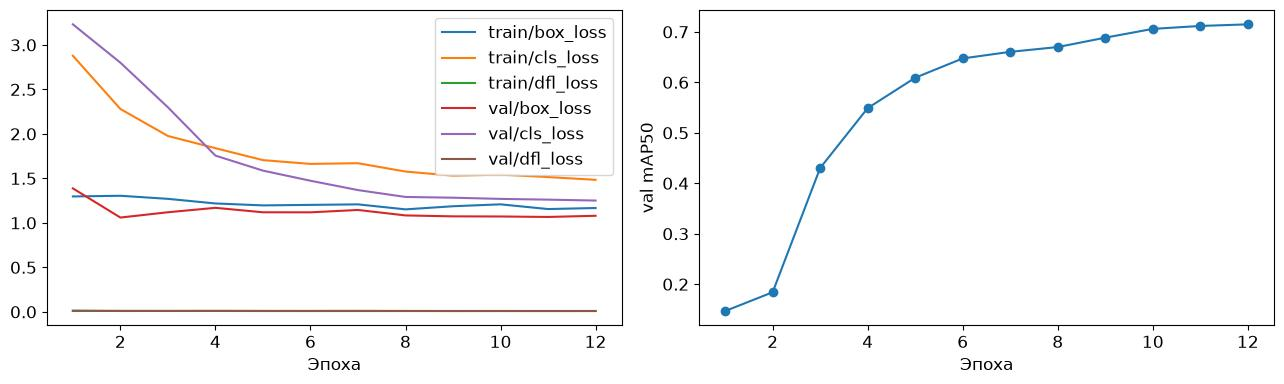

In [22]:
history = read_results(run_dir)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for key, values in history.items():
    if key.endswith('_loss'):
        axes[0].plot(history['epoch'], values, label=key)
map_key = 'metrics/mAP50(B)'
axes[1].plot(history['epoch'], history[map_key], marker='o')
axes[1].set_ylabel('val mAP50'); axes[0].legend()
for ax in axes:
    ax.set_xlabel('Эпоха')
plt.tight_layout(); plt.show()

Взял 384 пикселя для баланса между разрешением тромбоцитов и стоимостью двух прогонов. Батч 8 ограничивает расход общей памяти M4. AdamW с начальным шагом 0,001 адаптирует предобученные веса. Для мазка допустимы оба отражения; доля mosaic снижена до 0,3, чтобы сохранить естественный масштаб большинства кадров. Бюджет — 12 эпох, patience — 5. За 12 эпох train/cls_loss снизился с 2,878 до 1,484, val/cls_loss — с 3,231 до 1,251. На val mAP50 вырос с 0,147 до 0,715, причём на последней эпохе всё ещё рос. Устойчивого расхождения кривых не видно; более длинный прогон стоит проверить отдельно.

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [23]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=False, verbose=False, **kw)

Ultralytics 8.4.40 🚀 Python-3.13.15 torch-2.15.0 MPS (Apple M4)


YOLO26n summary (fused): 122 layers, 2,375,421 parameters, 0 gradients, 5.2 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 907.2±197.3 MB/s, size: 20.5 KB)


val: Scanning /Users/kolya/Documents/university/глубокое обучение/hw2_students/data/yolo/labels/val.cache... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87 91.2Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 9% ━─────────── 1/11 1.7it/s 0.2s<5.7s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 18% ━━────────── 2/11 4.0it/s 0.3s<2.2s

... (17 outputs left out)

                   all         72        945      0.594      0.688      0.704      0.481


Speed: 0.2ms preprocess, 2.3ms inference, 0.0ms loss, 0.2ms postprocess per image


Results saved to /Users/kolya/Documents/university/глубокое обучение/hw2_students/runs_hw2/full/metrics_test


test {
 "map50": 0.7035725835043767,
 "map50_95": 0.48092977434144196,
 "precision": 0.5939524279627292,
 "recall": 0.6881956100973072,
 "per_class": {
  "RBC": {
   "precision": 0.6647384055489374,
   "recall": 0.6608695652173913,
   "map50": 0.7233223488175999,
   "map50_95": 0.5123924121872248
  },
  "WBC": {
   "precision": 0.6113170077458864,
   "recall": 0.664586830291922,
   "map50": 0.7110170133501783,
   "map50_95": 0.5846918814506596
  },
  "Platelets": {
   "precision": 0.5058018705933639,
   "recall": 0.7391304347826086,
   "map50": 0.6763783883453516,
   "map50_95": 0.34570502938644154
  }
 }
}


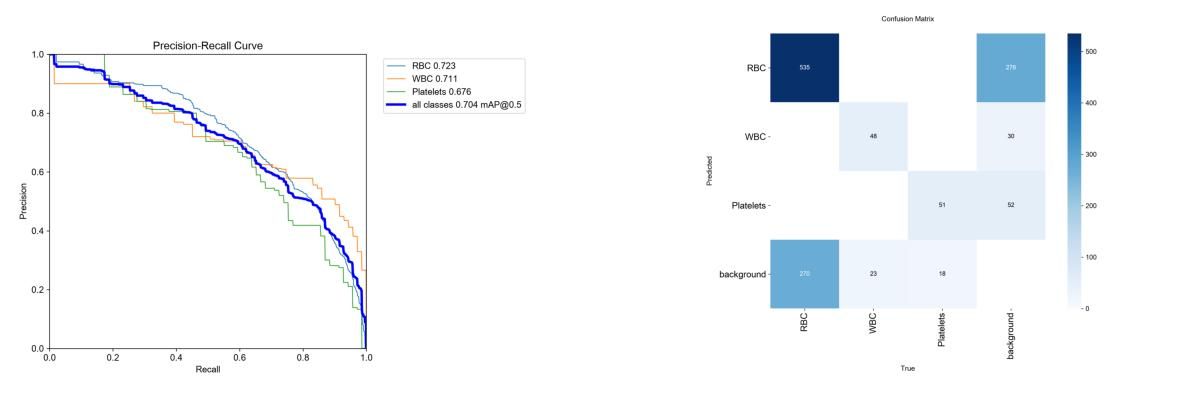

mAP50 своей функцией: 0.6936150446056324


In [24]:
def summarize_metrics(result):
    b = result.box
    per_class = {}
    for row, k in enumerate(b.ap_class_index):
        p, r, ap50, ap = b.class_result(row)
        per_class[CLASSES[int(k)]] = dict(precision=p, recall=r, map50=ap50, map50_95=ap)
    return dict(map50=b.map50, map50_95=b.map, precision=b.mp, recall=b.mr, per_class=per_class)

split_metrics = {}
for split in ('val', 'test'):
    result = val_metrics(best, split, 'metrics_' + split, plots=True)
    split_metrics[split] = summarize_metrics(result)
    print(split, json.dumps(split_metrics[split], indent=1))
    if split == FINAL_SPLIT:
        fig, axes = plt.subplots(1, 2, figsize=(15, 6))
        for ax, pattern in zip(axes, ('*PR_curve.png', 'confusion_matrix.png')):
            ax.imshow(plt.imread(next(Path(result.save_dir).glob(pattern))))
            ax.axis('off')
        plt.show()
FINAL = dict(split_metrics[FINAL_SPLIT])
final_preds = predict_records(best, records[FINAL_SPLIT], batch=BATCH)
FINAL['custom_map50'], _ = evaluate_map50(final_preds, records[FINAL_SPLIT], len(CLASSES))
print('mAP50 своей функцией:', FINAL['custom_map50'])

In [25]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': np.float64(0.7036),
 'map50_95': np.float64(0.4809),
 'precision': np.float64(0.594),
 'recall': np.float64(0.6882),
 'custom_map50': 0.6936}

Столбец background показывает ложные детекции, строка background — пропущенные объекты. mAP50–95 учитывает пороги IoU до 0,95, поэтому чувствительнее к смещению границ, особенно у маленьких тромбоцитов. Для сверки использованы те же test-кадры: наша функция интегрирует ступенчатую PR-кривую, а Ultralytics использует интерполяцию и свой порядок сопоставления боксов. На test mAP50 составил 0,704 в Ultralytics и 0,694 при самостоятельном подсчёте. Наиболее чувствительны к строгой локализации тромбоциты: AP50 0,676 и AP50–95 0,346; у крупных WBC соответствующие значения 0,711 и 0,585.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [26]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    a, b = a.reshape(-1, 4), b.reshape(-1, 4)
    wh = np.minimum(a[:, None, 2:], b[:, 2:]) - np.maximum(a[:, None, :2], b[:, :2])
    inter = np.maximum(wh, 0).prod(axis=2)
    union = (np.maximum(a[:, 2:]-a[:, :2], 0).prod(axis=1)[:, None]
             + np.maximum(b[:, 2:]-b[:, :2], 0).prod(axis=1) - inter)
    return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    found = np.zeros(len(gt['boxes']), bool)
    explained = found.copy()
    cats = ['background'] * len(ious)
    for i in np.argsort(-np.asarray(pred['scores']), kind='stable'):
        same = np.asarray(gt['labels']) == pred['labels'][i]
        overlap = ious[i]
        candidates = [('tp', same & ~found & (overlap >= iou_hit)),
                      ('class', ~same & (overlap >= iou_hit)),
                      ('localization', same & ~found & (overlap >= iou_loc) & (overlap < iou_hit))]
        for kind, mask in candidates:
            if mask.any():
                j = np.where(mask, overlap, -1).argmax()
                explained[j] = True
                if kind == 'tp':
                    found[j] = True
                cats[i] = kind
                break
    return cats, np.flatnonzero(~explained).tolist()

In [27]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


Число и доля событий (включая TP): {'tp': (773, 0.463), 'class': (0, 0.0), 'localization': (33, 0.02), 'background': (516, 0.309), 'missed': (346, 0.207)}
По классам (для детекций — предсказанный класс): {'RBC': Counter({'tp': 656, 'background': 411, 'missed': 293, 'localization': 33}), 'WBC': Counter({'tp': 60, 'missed': 27, 'background': 24}), 'Platelets': Counter({'background': 81, 'tp': 57, 'missed': 26})}


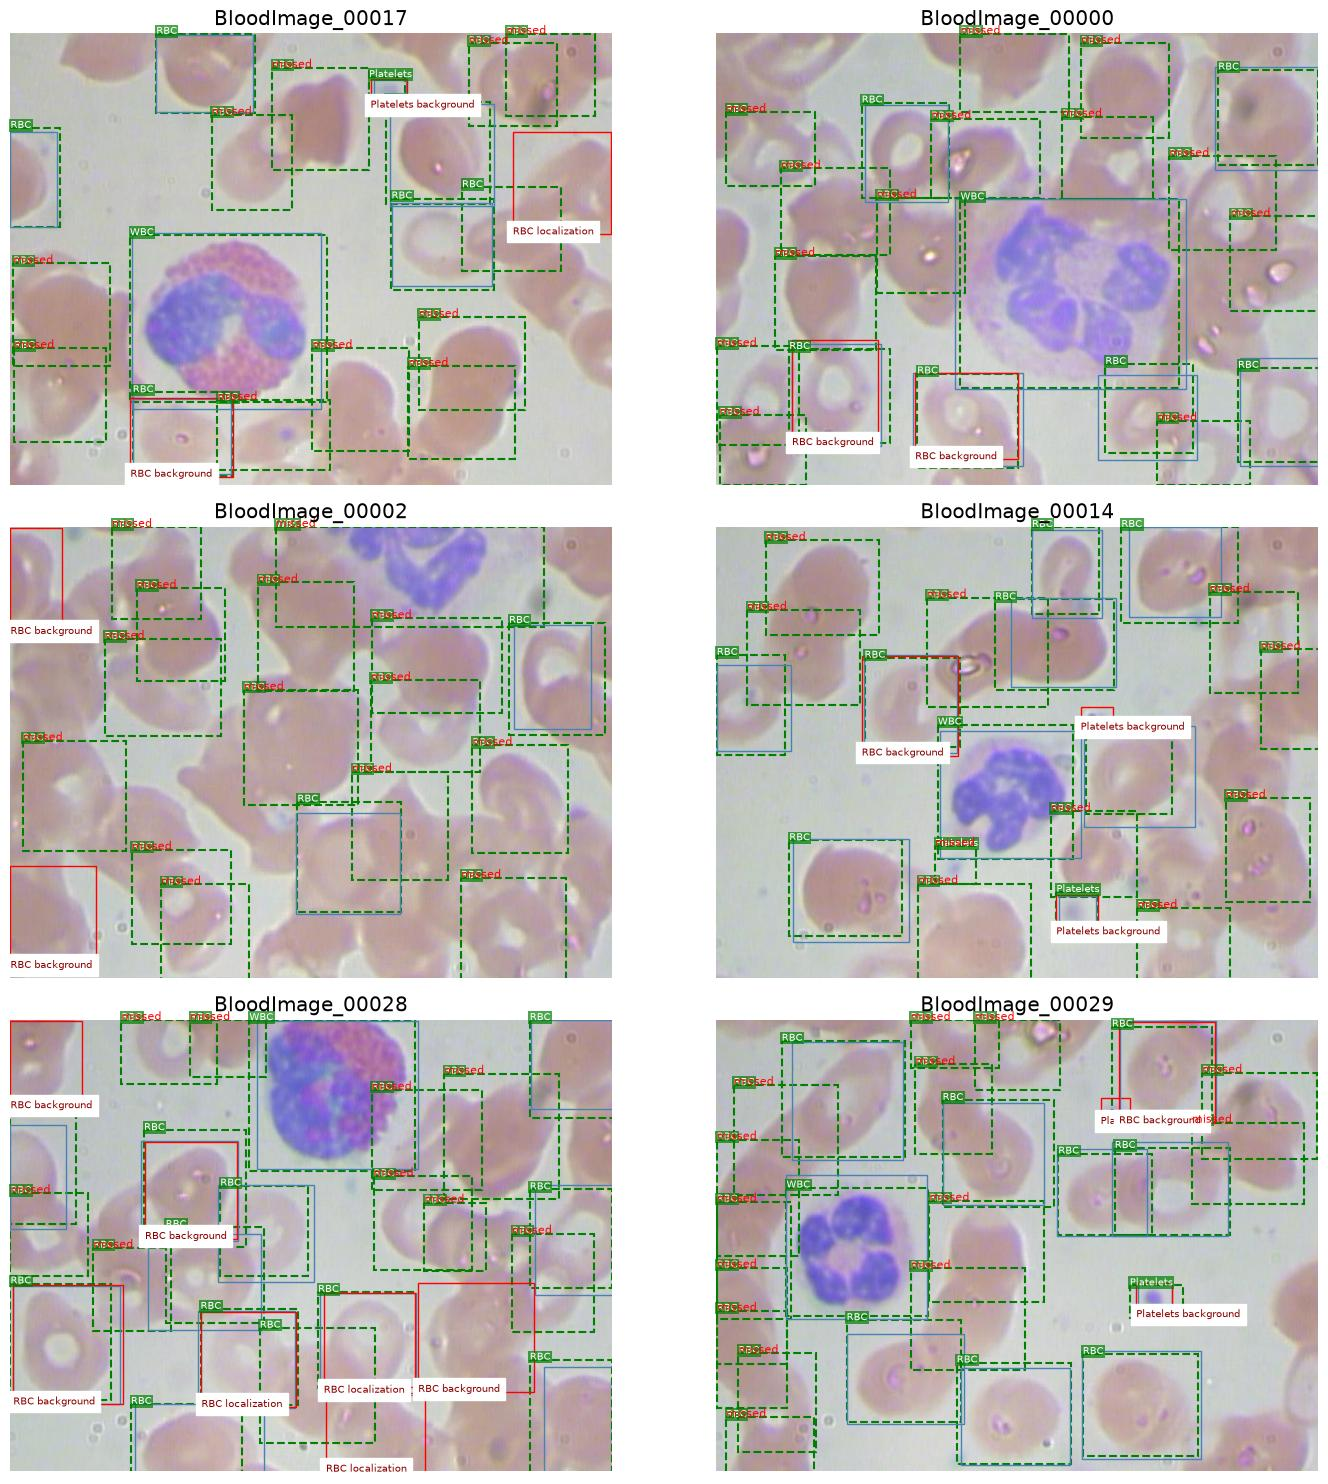

In [28]:
val_preds = predict_records(best, records['val'], conf=CONF_ERRORS, batch=BATCH)
by_class = {name: Counter() for name in CLASSES}
examples = []
for idx, (pred, gt) in enumerate(zip(val_preds, records['val'])):
    cats, missed = categorize_predictions(pred, gt)
    for kind, cls in zip(cats, pred['labels']):
        by_class[CLASSES[cls]][kind] += 1
    for j in missed:
        by_class[CLASSES[gt['labels'][j]]]['missed'] += 1
    kinds = set(cats) - {'tp'}
    if missed:
        kinds.add('missed')
    if kinds:
        examples.append((idx, kinds, cats, missed))
ERRORS = {kind: sum(counts[kind] for counts in by_class.values()) for kind in ERROR_TYPES}
print('Число и доля событий (включая TP):', {k: (v, round(v/max(sum(ERRORS.values()), 1), 3)) for k, v in ERRORS.items()})
print('По классам (для детекций — предсказанный класс):', by_class)
shown, covered = [], set()
while examples and len(shown) < 6:
    item = max(examples, key=lambda x: len(x[1] - covered))
    examples.remove(item)
    shown.append(item)
    covered.update(item[1])
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
for ax in axes.flat:
    ax.axis('off')
for ax, (idx, kinds, cats, missed) in zip(axes.flat, shown):
    gt, pred = records['val'][idx], val_preds[idx]
    draw_boxes(ax, Image.open(gt['image']), gt['boxes'], gt['labels'], CLASSES, color='green', linestyle='--')
    # Ошибки красные, правильные детекции синие; подписями отмечены категории ошибок.
    for box, cls, kind in zip(pred['boxes'], pred['labels'], cats):
        x, y, x2, y2 = box
        ax.add_patch(Rectangle((x,y), x2-x, y2-y, fill=False, lw=1, edgecolor='steelblue' if kind=='tp' else 'red'))
        if kind != 'tp':
            ax.text(x, y2, f'{CLASSES[cls]} {kind}', color='darkred', fontsize=7, backgroundcolor='white')
    for j in missed:
        ax.text(*gt['boxes'][j, :2], 'missed', color='red', fontsize=8)
    ax.set_title(gt['image'].stem)
plt.tight_layout(); plt.show()

При conf ≥ 0,25 наиболее частая ошибка — background: 516 из 895 ошибок (58%), из них 411 рамок класса RBC. На BloodImage_00000 видны красная и синяя рамки вокруг одного эритроцита: повторная детекция считается лишней. В левом нижнем углу BloodImage_00002 красная рамка охватывает частично видимую клетку без зелёной рамки; здесь расхождение может объясняться правилами разметки края кадра. В первую очередь я бы проверил на val подавление дублей и изменение порога, одновременно отслеживая recall: уже при текущем пороге осталось 346 пропусков.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [29]:
n_frozen = len(arch.yaml['backbone'])
model_frozen, elapsed, frozen_dir = train_yolo('frozen', freeze=n_frozen, **TRAIN_ARGS)
frozen_best = YOLO(frozen_dir / 'weights/best.pt')
frozen_val = summarize_metrics(val_metrics(frozen_best, 'val', 'metrics_frozen', plots=False))
ABLATION = dict(parameter='freeze', split='val', variants=[])
for freeze, metric, seconds in [(0, split_metrics['val'], RUN_TIMES['train']), (n_frozen, frozen_val, elapsed)]:
    ABLATION['variants'].append(dict(freeze=freeze, map50=metric['map50'], map50_95=metric['map50_95'], train_time_sec=seconds))
print(ABLATION)

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.40 🚀 Python-3.13.15 torch-2.15.0 MPS (Apple M4)


engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=12, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=11, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=384, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.3, multi_scale=0.0, name=frozen, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=5, perspective=0.0, plots=False, pose=12.0, pretrained=True, profile=False, project=/Users/kolya/D

Overriding model.yaml nc=80 with nc=3



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (604 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 15.7it/s 0.7s

                   all         87       1138      0.641      0.571      0.641      0.429


Speed: 0.2ms preprocess, 4.6ms inference, 0.0ms loss, 0.3ms postprocess per image


{'parameter': 'freeze', 'split': 'val', 'variants': [{'freeze': 0, 'map50': np.float64(0.7151213180517696), 'map50_95': np.float64(0.49796502038724133), 'train_time_sec': 126.38126370799728}, {'freeze': 11, 'map50': np.float64(0.6413616568700753), 'map50_95': np.float64(0.4290404553521558), 'train_time_sec': 89.91562200000044}]}


В обоих прогонах одинаковые исходные веса, изображения, seed, разрешение, оптимизатор и бюджет эпох. Во втором прогоне веса backbone зафиксированы, обновляются только neck и голова детектора. При полном обучении val mAP50/mAP50–95 составили 0,715/0,498 за 126 с. Заморозка 11 слоёв дала 0,641/0,429 за 90 с. Для этого датасета я бы оставил backbone обучаемым: он даёт более высокую точность локализации.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

На 72 тестовых снимках исходная модель COCO получила нулевой mAP50 из-за отсутствия классов клеток в её словаре. Цветовая эвристика дала 0,233 mAP50, дообученная YOLO26n — 0,704. При более строгой оценке mAP50–95 снизился до 0,481; самый низкий результат у мелких тромбоцитов (0,346). На val при conf ≥ 0,25 чаще всего встречались лишние рамки (516), в том числе дубли и детекции на краях кадра. При заморозке backbone val mAP50–95 изменился с 0,498 до 0,429. Сравнение ограничено одним seed и 87 снимками val; PyTorch предупреждает, что на MPS результат отдельных операций может различаться между запусками. Следующим экспериментом я бы проверил большее разрешение входа при том же числе эпох и сравнил AP тромбоцитов, время обучения и долю дублей.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [31]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

Дополнительная задача не выбрана.

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [32]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

Дополнительная задача не выбрана.

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [33]:
if '6.3' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

Дополнительная задача не выбрана.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [34]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

Дополнительная задача не выбрана.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [35]:
if '6.5' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

Дополнительная задача не выбрана.